# 03 — Modeling & Evaluasi
Membandingkan tiga algoritma estimasi harga tiket pada data hasil `02_Preprocessing`:

| Model | Fitur waktu pemesanan | Catatan |
|---|---|---|
| **Multiple Linear Regression (MLR)** | `days_group` (dummy) | Model utama; koefisiennya dipakai untuk menentukan faktor paling berpengaruh |
| **Decision Tree Regression** | `days_left` asli | Bisa menangkap pola tidak linear; memberi *feature importance* |
| **KNN Regression** | `days_left` asli | Butuh scaling; paling lambat saat prediksi |

Semua model dilatih dengan target `log_price`. Prediksi dikembalikan ke rupee (`exp`) sebelum menghitung MAE, RMSE, dan R², supaya hasilnya mudah dibaca dan adil dibandingkan.


In [1]:
# Sel 1 — muat data
from google.colab import drive
drive.mount('/content/drive')

import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = '/content/drive/MyDrive/Project Data mining'
train = pd.read_csv(f'{ROOT}/Dataset/Processed/train.csv')
test  = pd.read_csv(f'{ROOT}/Dataset/Processed/test.csv')
OUT = f'{ROOT}/Evaluasi'
os.makedirs(OUT, exist_ok=True)
print("Train:", train.shape, "| Test:", test.shape)

Mounted at /content/drive
Train: (240122, 34) | Test: (60031, 34)


In [2]:
# Sel 2 — susun fitur untuk tiap model
target = 'log_price'
days_dummies = [c for c in train.columns if c.startswith('days_group_')]
basis = [c for c in train.columns if c not in ['price', 'log_price', 'days_left'] + days_dummies]

fitur_mlr  = basis + days_dummies          # MLR: kelompok waktu pemesanan
fitur_tree = basis + ['days_left']         # DT & KNN: days_left asli

y_train, y_test = train[target], test[target]
harga_test = test['price']                 # harga asli (rupee) untuk evaluasi
print("Jumlah fitur MLR :", len(fitur_mlr))
print("Jumlah fitur DT/KNN:", len(fitur_tree))

Jumlah fitur MLR : 31
Jumlah fitur DT/KNN: 29


In [3]:
# Sel 3 — fungsi evaluasi (dipakai semua model)
hasil = []
def evaluasi(nama, pred_log, waktu):
    pred_rp = np.exp(pred_log)
    baris = {
        'Model': nama,
        'MAE (INR)':  mean_absolute_error(harga_test, pred_rp),
        'RMSE (INR)': float(np.sqrt(mean_squared_error(harga_test, pred_rp))),
        'R² (INR)':   r2_score(harga_test, pred_rp),
        'R² (log)':   r2_score(y_test, pred_log),
        'Waktu (detik)': waktu,
    }
    hasil.append(baris)
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in baris.items()})
    return pred_rp

## Model 1 — Multiple Linear Regression
Memakai `statsmodels` agar keluar tabel koefisien lengkap dengan p-value (bisa langsung dikutip ke laporan).

In [4]:
# Sel 4 — cek multikolinearitas (VIF) pada sampel 20.000 baris
X_vif = sm.add_constant(train[fitur_mlr].sample(20000, random_state=42).astype(float))
vif = pd.DataFrame({
    'fitur': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
}).query("fitur != 'const'").sort_values('VIF', ascending=False)
print(vif.head(10).to_string(index=False))
print("\nAturan umum: VIF > 10 = multikolinearitas serius, 5–10 = perlu diwaspadai.")

                       fitur      VIF
             airline_Vistara 6.053600
           airline_Air_India 5.131876
              airline_Indigo 3.348870
          arrival_time_Night 2.493212
        arrival_time_Evening 2.332739
            airline_GO_FIRST 2.290962
        arrival_time_Morning 2.229113
      departure_time_Evening 1.975753
      departure_time_Morning 1.957251
departure_time_Early_Morning 1.955113

Aturan umum: VIF > 10 = multikolinearitas serius, 5–10 = perlu diwaspadai.


In [5]:
# Sel 5 — latih MLR
X_train_mlr = sm.add_constant(train[fitur_mlr].astype(float))
X_test_mlr  = sm.add_constant(test[fitur_mlr].astype(float))

t0 = time.time()
mlr = sm.OLS(y_train, X_train_mlr).fit()
waktu = time.time() - t0
print(mlr.summary())

                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.923
Model:                            OLS   Adj. R-squared:                  0.923
Method:                 Least Squares   F-statistic:                 9.340e+04
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:03:23   Log-Likelihood:                -57864.
No. Observations:              240122   AIC:                         1.158e+05
Df Residuals:                  240090   BIC:                         1.161e+05
Df Model:                          31                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const           

In [6]:
# Sel 6 — evaluasi MLR
pred_mlr = evaluasi('Multiple Linear Regression', mlr.predict(X_test_mlr), waktu)

{'Model': 'Multiple Linear Regression', 'MAE (INR)': 4935.315, 'RMSE (INR)': 9053.8176, 'R² (INR)': 0.841, 'R² (log)': 0.9246, 'Waktu (detik)': 0.4784}


In [7]:
# Sel 7 — terjemahkan koefisien menjadi persen pengaruh terhadap harga
koef = pd.DataFrame({'koefisien': mlr.params, 'p_value': mlr.pvalues}).drop('const')
koef['pengaruh_%'] = (np.exp(koef['koefisien']) - 1) * 100
koef = koef.reindex(koef['pengaruh_%'].abs().sort_values(ascending=False).index)
koef.round(4).to_csv(f'{OUT}/koefisien_mlr.csv')
print(koef.round(4).to_string())

                              koefisien  p_value  pengaruh_%
is_business                      2.0374   0.0000    667.0506
days_group_1-3                   0.7191   0.0000    105.2567
airline_Vistara                  0.6471   0.0000     91.0042
airline_Air_India                0.5216   0.0000     68.4741
days_group_4-10                  0.4942   0.0000     63.9241
airline_SpiceJet                 0.4701   0.0000     60.0222
airline_GO_FIRST                 0.4429   0.0000     55.7279
days_group_11-15                 0.4081   0.0000     50.3989
stops                            0.3756   0.0000     45.5893
airline_Indigo                   0.3262   0.0000     38.5662
source_city_Kolkata              0.1398   0.0000     15.0083
destination_city_Kolkata         0.1060   0.0000     11.1830
destination_city_Hyderabad      -0.0961   0.0000     -9.1643
source_city_Hyderabad           -0.0831   0.0000     -7.9760
arrival_time_Early_Morning      -0.0731   0.0000     -7.0523
source_city_Mumbai      

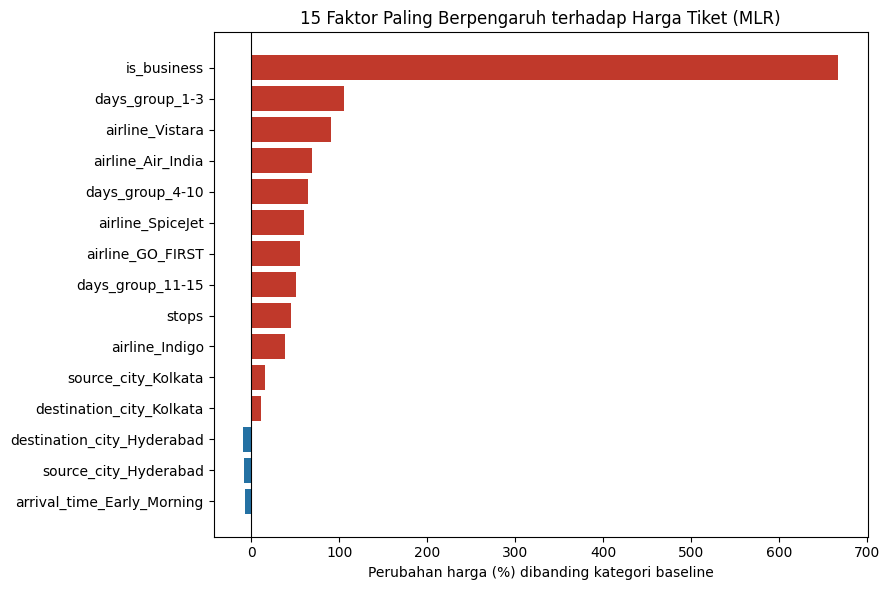

In [8]:
# Sel 8 — grafik 15 faktor paling berpengaruh
top = koef.head(15).iloc[::-1]
warna = ['#c0392b' if v > 0 else '#2471a3' for v in top['pengaruh_%']]
plt.figure(figsize=(9, 6))
plt.barh(top.index, top['pengaruh_%'], color=warna)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Perubahan harga (%) dibanding kategori baseline')
plt.title('15 Faktor Paling Berpengaruh terhadap Harga Tiket (MLR)')
plt.tight_layout()
plt.savefig(f'{OUT}/faktor_berpengaruh_mlr.png', dpi=150)
plt.show()

## Model 2 — Decision Tree Regression
`max_depth` dipilih dengan data validasi (20% dari train), **bukan** data test, supaya evaluasi akhir tetap jujur.

In [9]:
# Sel 9 — pilih max_depth terbaik
X_tr, X_val, y_tr, y_val = train_test_split(train[fitur_tree], y_train, test_size=0.2, random_state=42)
skor = {}
for d in [5, 10, 15, 20, 25]:
    m = DecisionTreeRegressor(max_depth=d, min_samples_leaf=5, random_state=42).fit(X_tr, y_tr)
    skor[d] = r2_score(y_val, m.predict(X_val))
    print(f"max_depth={d:>2}  R² validasi (log) = {skor[d]:.4f}")
best_depth = max(skor, key=skor.get)
print("\nmax_depth terbaik:", best_depth)

max_depth= 5  R² validasi (log) = 0.9309
max_depth=10  R² validasi (log) = 0.9560
max_depth=15  R² validasi (log) = 0.9680
max_depth=20  R² validasi (log) = 0.9747
max_depth=25  R² validasi (log) = 0.9781

max_depth terbaik: 25


In [10]:
# Sel 10 — latih ulang di seluruh train & evaluasi
t0 = time.time()
dt = DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=5, random_state=42)
dt.fit(train[fitur_tree], y_train)
waktu = time.time() - t0
pred_dt = evaluasi(f'Decision Tree (depth={best_depth})', dt.predict(test[fitur_tree]), waktu)

{'Model': 'Decision Tree (depth=25)', 'MAE (INR)': 1217.7356, 'RMSE (INR)': 2997.5339, 'R² (INR)': 0.9826, 'R² (log)': 0.98, 'Waktu (detik)': 2.2316}


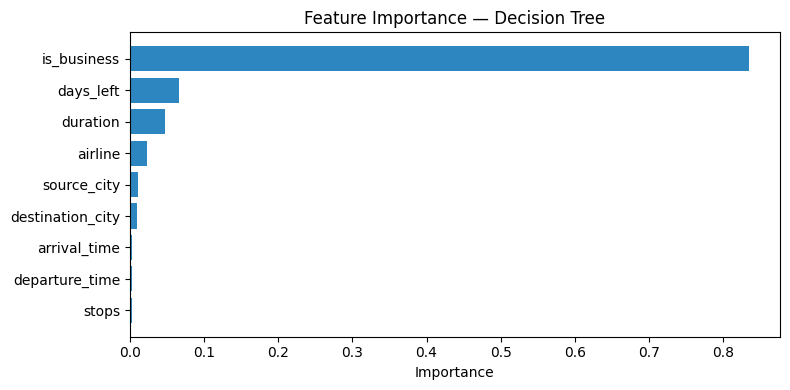

is_business         0.8349
days_left           0.0669
duration            0.0470
airline             0.0228
source_city         0.0105
destination_city    0.0093
arrival_time        0.0031
departure_time      0.0030
stops               0.0026
dtype: float64


In [11]:
# Sel 11 — feature importance Decision Tree (dummy digabung kembali ke variabel asal)
imp = pd.Series(dt.feature_importances_, index=fitur_tree)
grup = imp.groupby(lambda c: next((p for p in ['airline', 'source_city', 'destination_city',
                                               'departure_time', 'arrival_time'] if c.startswith(p)), c)).sum()
grup = grup.sort_values()
plt.figure(figsize=(8, 4))
plt.barh(grup.index, grup.values, color='#2e86c1')
plt.title('Feature Importance — Decision Tree'); plt.xlabel('Importance')
plt.tight_layout(); plt.savefig(f'{OUT}/feature_importance_dt.png', dpi=150); plt.show()
print(grup.sort_values(ascending=False).round(4))

## Model 3 — KNN Regression
Fitur numerik (`stops`, `duration`, `days_left`) di-scaling ke rentang 0–1 agar setara dengan kolom dummy. Scaler **di-fit di train saja**.
Pemilihan `k` memakai sampel kecil karena KNN lambat; prediksi akhir di seluruh data test bisa memakan beberapa menit.

In [12]:
# Sel 12 — scaling
num = ['stops', 'duration', 'days_left']
scaler = MinMaxScaler().fit(train[num])
Xtr_knn, Xte_knn = train[fitur_tree].copy(), test[fitur_tree].copy()
Xtr_knn[num] = scaler.transform(train[num])
Xte_knn[num] = scaler.transform(test[num])

In [13]:
# Sel 13 — pilih k terbaik (sampel 50.000 train, 10.000 validasi)
idx = np.random.RandomState(42).permutation(len(Xtr_knn))
fit_idx, val_idx = idx[:50000], idx[50000:60000]
skor_k = {}
for k in [3, 5, 7, 9, 15, 25]:
    m = KNeighborsRegressor(n_neighbors=k, n_jobs=-1).fit(Xtr_knn.iloc[fit_idx], y_train.iloc[fit_idx])
    skor_k[k] = r2_score(y_train.iloc[val_idx], m.predict(Xtr_knn.iloc[val_idx]))
    print(f"k={k:>2}  R² validasi (log) = {skor_k[k]:.4f}")
best_k = max(skor_k, key=skor_k.get)
print("\nk terbaik:", best_k)

k= 3  R² validasi (log) = 0.9488
k= 5  R² validasi (log) = 0.9419
k= 7  R² validasi (log) = 0.9361
k= 9  R² validasi (log) = 0.9303
k=15  R² validasi (log) = 0.9127
k=25  R² validasi (log) = 0.8897

k terbaik: 3


In [14]:
# Sel 14 — latih di seluruh train & evaluasi (bisa beberapa menit)
t0 = time.time()
knn = KNeighborsRegressor(n_neighbors=best_k, n_jobs=-1).fit(Xtr_knn, y_train)
pred_knn_log = knn.predict(Xte_knn)
waktu = time.time() - t0
pred_knn = evaluasi(f'KNN Regression (k={best_k})', pred_knn_log, waktu)

{'Model': 'KNN Regression (k=3)', 'MAE (INR)': 1785.7801, 'RMSE (INR)': 3855.6922, 'R² (INR)': 0.9712, 'R² (log)': 0.9747, 'Waktu (detik)': 67.0936}


## Perbandingan Model

In [15]:
# Sel 15 — tabel perbandingan
tabel = pd.DataFrame(hasil).set_index('Model').round(4)
tabel.to_csv(f'{OUT}/perbandingan_model.csv')
tabel

,MAE (INR),RMSE (INR),R² (INR),R² (log),Waktu (detik)
Model,,,,,
Multiple Linear Regression,4935.3150,9053.8176,0.8410,0.9246,0.4784
Decision Tree (depth=25),1217.7356,2997.5339,0.9826,0.9800,2.2316
KNN Regression (k=3),1785.7801,3855.6922,0.9712,0.9747,67.0936


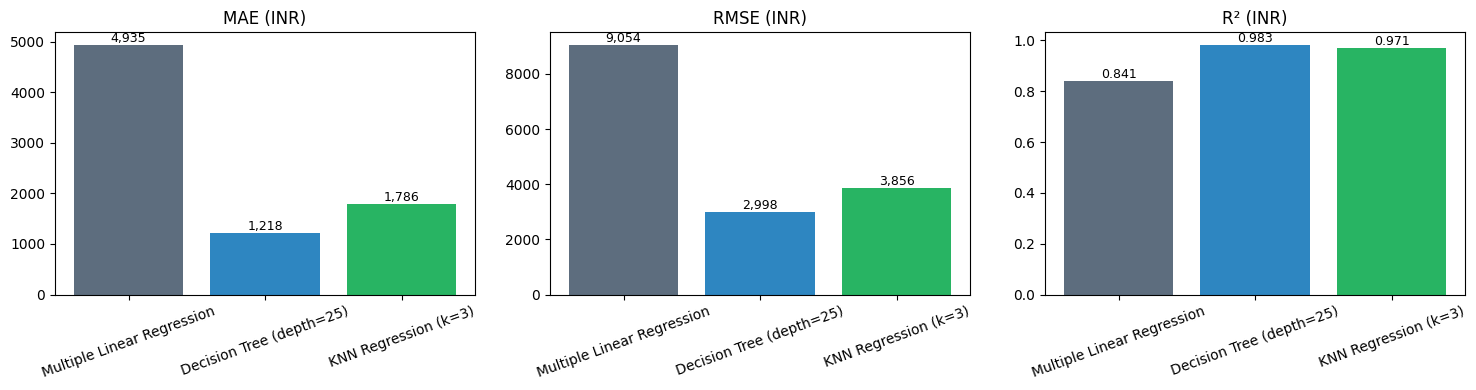

In [16]:
# Sel 16 — grafik perbandingan metrik
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, m in zip(ax, ['MAE (INR)', 'RMSE (INR)', 'R² (INR)']):
    a.bar(tabel.index, tabel[m], color=['#5d6d7e', '#2e86c1', '#28b463'])
    a.set_title(m); a.tick_params(axis='x', rotation=20)
    for i, v in enumerate(tabel[m]):
        a.text(i, v, f'{v:,.3f}' if 'R²' in m else f'{v:,.0f}', ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.savefig(f'{OUT}/perbandingan_metrik.png', dpi=150); plt.show()

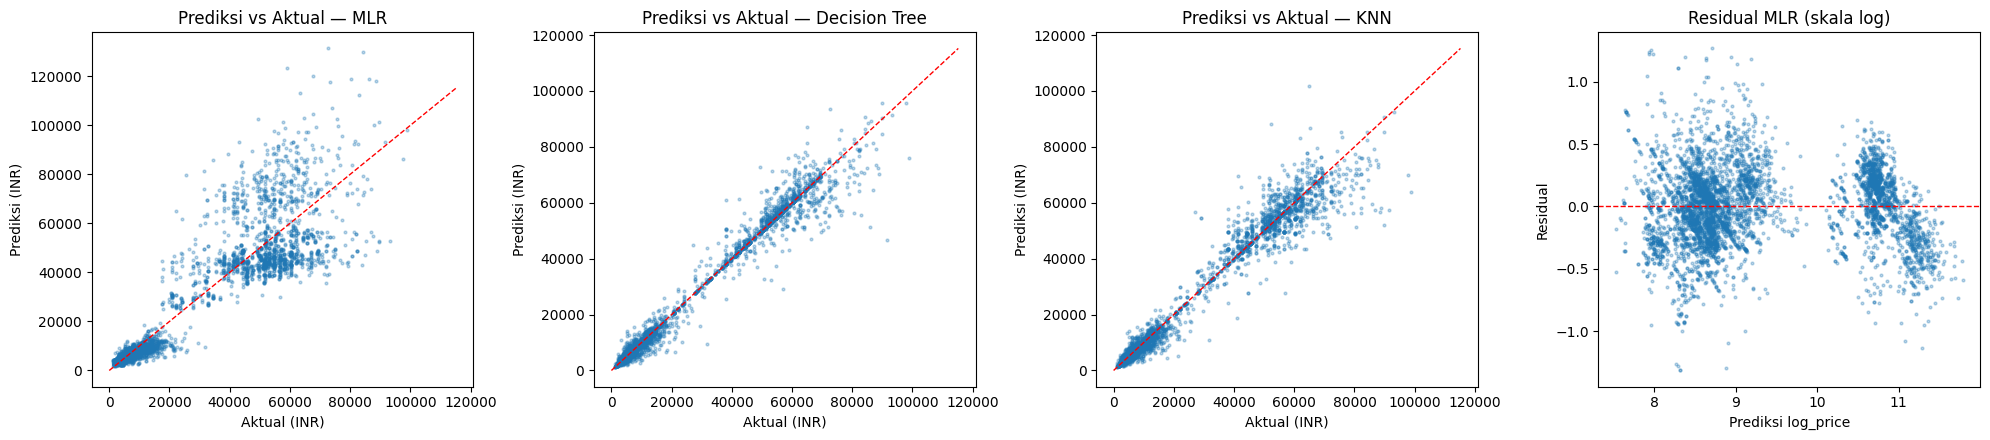

In [17]:
# Sel 17 — prediksi vs aktual & residual (sampel 5.000 titik agar ringan)
s = np.random.RandomState(0).choice(len(harga_test), 5000, replace=False)
fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
for a, (nama, p) in zip(ax[:3], [('MLR', pred_mlr), ('Decision Tree', pred_dt), ('KNN', pred_knn)]):
    a.scatter(harga_test.iloc[s], np.asarray(p)[s], s=4, alpha=0.3)
    lim = [0, harga_test.max()]
    a.plot(lim, lim, 'r--', linewidth=1)
    a.set_title(f'Prediksi vs Aktual — {nama}'); a.set_xlabel('Aktual (INR)'); a.set_ylabel('Prediksi (INR)')
resid = y_test - mlr.predict(X_test_mlr)
ax[3].scatter(mlr.predict(X_test_mlr).iloc[s], resid.iloc[s], s=4, alpha=0.3)
ax[3].axhline(0, color='r', linestyle='--', linewidth=1)
ax[3].set_title('Residual MLR (skala log)'); ax[3].set_xlabel('Prediksi log_price'); ax[3].set_ylabel('Residual')
plt.tight_layout(); plt.savefig(f'{OUT}/prediksi_vs_aktual.png', dpi=150); plt.show()

## Catatan untuk laporan
- Semua grafik & tabel otomatis tersimpan di folder **Evaluasi**.
- **R² (log)** = seberapa baik model menjelaskan variasi log harga; **R² (INR)** = setelah dikembalikan ke rupee.
- Bandingkan urutan faktor dari koefisien MLR (Sel 7–8) dengan feature importance Decision Tree (Sel 11). Jika keduanya sepakat (mis. kelas & waktu pemesanan teratas), kesimpulan faktor berpengaruh jadi lebih kuat.

## Perbaikan MLR — model terpisah per kelas
Plot residual MLR (Sel 17) menunjukkan pola miring di kelompok Business, artinya satu model untuk dua kelas tidak cukup. Dari EDA juga terlihat efek waktu pemesanan sangat berbeda: Economy naik ±2,7× saat dibeli mendadak, Business hanya ±17%. Model gabungan memaksa efek itu sama untuk kedua kelas. Solusinya: latih MLR terpisah untuk Economy dan Business.

In [18]:
# Sel 18 — MLR terpisah per kelas
fitur_kelas = [c for c in fitur_mlr if c != 'is_business']
pred_gabung = pd.Series(index=test.index, dtype=float)
efek = {}
t0 = time.time()
for kelas, flag in [('Economy', 0), ('Business', 1)]:
    tr, te = train[train['is_business'] == flag], test[test['is_business'] == flag]
    cols = [c for c in fitur_kelas if tr[c].nunique() > 1]          # buang dummy maskapai yang tidak punya kelas ini
    if kelas == 'Business':
        cols = [c for c in cols if c != 'airline_Air_India']        # Business hanya Vistara & Air India → Air India jadi baseline
    m = sm.OLS(tr[target], sm.add_constant(tr[cols].astype(float))).fit()
    pred_gabung.loc[te.index] = m.predict(sm.add_constant(te[cols].astype(float), has_constant='add'))
    efek[kelas] = (np.exp(m.params.drop('const')) - 1) * 100
    print(f"{kelas:9s}: R² train (log) = {m.rsquared:.4f}")
waktu = time.time() - t0
pred_mlr_kelas = evaluasi('MLR per kelas', pred_gabung.values, waktu)

efek_df = pd.DataFrame(efek).round(2)
efek_df.to_csv(f'{OUT}/pengaruh_per_kelas_mlr.csv')
print("\nPengaruh (%) terhadap harga, per kelas:")
print(efek_df.loc[[c for c in efek_df.index if c.startswith('days_group') or c in ['stops', 'duration'] or c.startswith('airline')]])

tabel = pd.DataFrame(hasil).set_index('Model').round(4)
tabel.to_csv(f'{OUT}/perbandingan_model.csv')
tabel

Economy  : R² train (log) = 0.6705
Business : R² train (log) = 0.5972
{'Model': 'MLR per kelas', 'MAE (INR)': 3209.7491, 'RMSE (INR)': 5673.0095, 'R² (INR)': 0.9376, 'R² (log)': 0.9424, 'Waktu (detik)': 0.5717}

Pengaruh (%) terhadap harga, per kelas:
                   Economy  Business
airline_Air_India    69.79       NaN
airline_GO_FIRST     55.54       NaN
airline_Indigo       36.02       NaN
airline_SpiceJet     53.45       NaN
airline_Vistara      86.29     16.36
days_group_1-3      161.22     18.26
days_group_11-15     80.08      0.63
days_group_4-10     105.74      4.25
duration              0.58     -0.02
stops                37.87     82.60


,MAE (INR),RMSE (INR),R² (INR),R² (log),Waktu (detik)
Model,,,,,
Multiple Linear Regression,4935.3150,9053.8176,0.8410,0.9246,0.4784
Decision Tree (depth=25),1217.7356,2997.5339,0.9826,0.9800,2.2316
KNN Regression (k=3),1785.7801,3855.6922,0.9712,0.9747,67.0936
MLR per kelas,3209.7491,5673.0095,0.9376,0.9424,0.5717


## Simpan model untuk prototype
Decision Tree dipakai di prototype karena paling akurat dan cepat. File disimpan ke folder **Prototipe**.

In [19]:
# Sel 19 — simpan model Decision Tree + daftar fitur
import joblib, json
PROTO = f'{ROOT}/Prototipe'
os.makedirs(PROTO, exist_ok=True)
joblib.dump(dt, f'{PROTO}/model_dt.joblib', compress=3)
with open(f'{PROTO}/fitur_dt.json', 'w') as f:
    json.dump(fitur_tree, f)
print("Ukuran model: %.1f MB" % (os.path.getsize(f'{PROTO}/model_dt.joblib') / 1e6))
print("Tersimpan di:", PROTO)

Ukuran model: 1.1 MB
Tersimpan di: /content/drive/MyDrive/Project Data mining/Prototipe
